# Lab 7: Fast Fourier Transform (FFT)

Ross A. Miranda
1034988497

## 1. Librerías

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa

from PIL import Image
from io import BytesIO
from google.colab import files
from scipy import integrate
from scipy.fft import fft, fft2, fftfreq, fftshift, ifft2
from scipy.signal import find_peaks

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (10, 4)

# Example 1: Chord – musical sound (Do mayor)


## 2. Cargar el archivo de audio

In [ ]:
# Seleccionar el archivo Nota_CM_piano.mp3 desde el computador
archivos_audio = files.upload()

if not archivos_audio:
    raise ValueError("No se seleccionó un archivo de audio.")

nombre_audio = next(iter(archivos_audio))
audio_bytes = BytesIO(archivos_audio[nombre_audio])

signal, sr = librosa.load(audio_bytes, sr=None)
signal = np.asarray(signal, dtype=float)

print(f"Archivo: {nombre_audio}")
print(f"Frecuencia de muestreo: {sr} Hz")
print(f"Número de muestras: {len(signal)}")
print(f"Duración: {len(signal)/sr:.3f} s")

Saving Nota_CM_piano.mp3 to Nota_CM_piano.mp3
Archivo: Nota_CM_piano.mp3
Frecuencia de muestreo: 44100 Hz
Número de muestras: 152064
Duración: 3.448 s


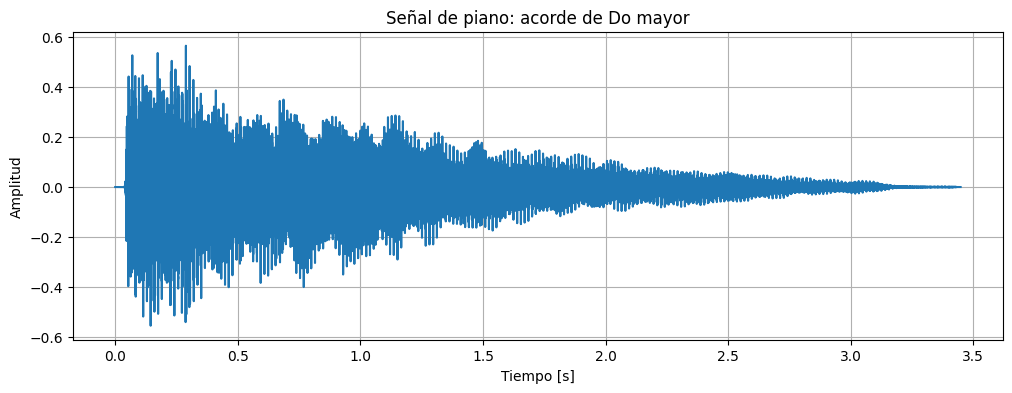

In [ ]:
# Vector de tiempo y representación de la señal
t = np.arange(len(signal)) / sr

plt.figure(figsize=(12, 4))
plt.plot(t, signal)
plt.grid(True)
plt.title("Señal de piano: acorde de Do mayor")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.show()

## 3. FFT usando NumPy y SciPy


Error máximo entre FFT de NumPy y SciPy: 5.084229945850415e-13


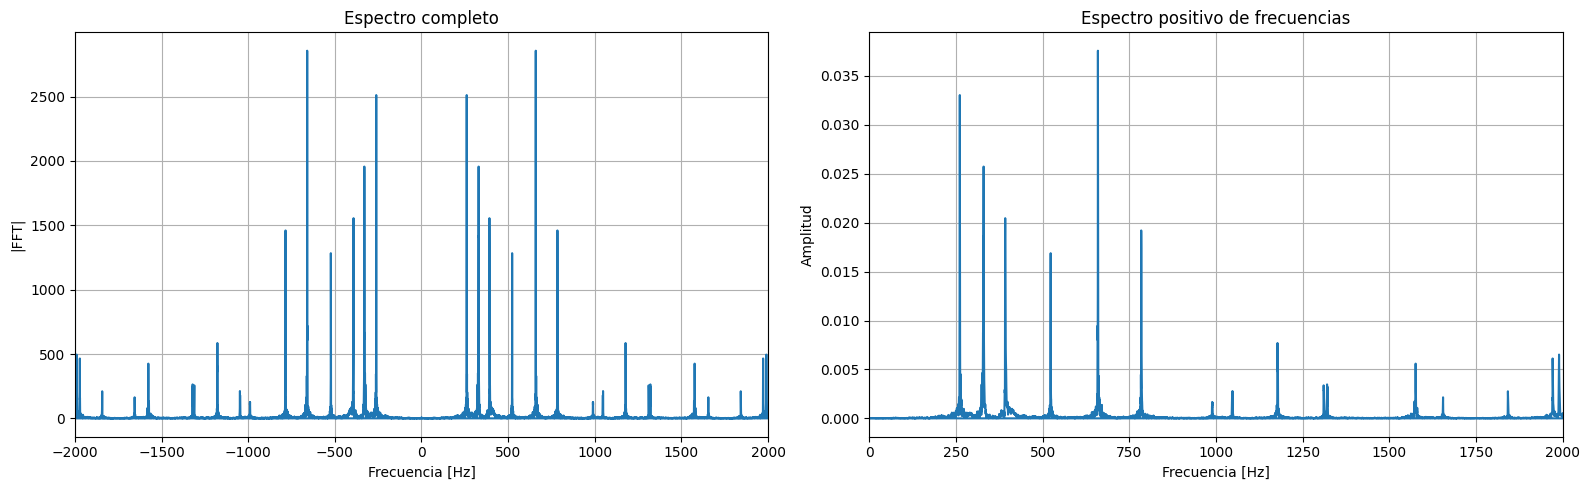

In [ ]:
N = len(signal)
Y_numpy = np.fft.fft(signal)
Y_scipy = fft(signal)
frecuencia = fftfreq(N, d=1/sr)

error_numpy_scipy = np.max(np.abs(Y_numpy - Y_scipy))
print("Error máximo entre FFT de NumPy y SciPy:", error_numpy_scipy)

# Espectro unilateral (frecuencias positivas)
if N % 2 == 0:
    frecuencias_pos = frecuencia[:N//2 + 1]
    amplitud_pos = 2.0/N * np.abs(Y_scipy[:N//2 + 1])
    amplitud_pos[0] /= 2
    amplitud_pos[-1] /= 2
else:
    frecuencias_pos = frecuencia[:(N+1)//2]
    amplitud_pos = 2.0/N * np.abs(Y_scipy[:(N+1)//2])

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].plot(frecuencia, np.abs(Y_scipy))
ax[0].set_title("Espectro completo")
ax[0].set_xlabel("Frecuencia [Hz]")
ax[0].set_ylabel("|FFT|")
ax[0].grid(True)
ax[0].set_xlim(-2000, 2000)

ax[1].plot(frecuencias_pos, amplitud_pos)
ax[1].set_title("Espectro positivo de frecuencias")
ax[1].set_xlabel("Frecuencia [Hz]")
ax[1].set_ylabel("Amplitud")
ax[1].set_xlim(0, 2000)
ax[1].grid(True)

plt.tight_layout()
plt.show()

### Frecuencias principales del acorde

Se identifican los picos de amplitud del espectro positivo. En un sonido musical pueden aparecer tanto las frecuencias fundamentales de las notas como sus armónicos.

Diez picos principales:
659.48 Hz -> amplitud 0.037576
261.01 Hz -> amplitud 0.033041
329.74 Hz -> amplitud 0.025733
392.09 Hz -> amplitud 0.020458
784.48 Hz -> amplitud 0.019204
523.18 Hz -> amplitud 0.016880
1177.73 Hz -> amplitud 0.007699
2110.69 Hz -> amplitud 0.006563
1990.04 Hz -> amplitud 0.006517
1971.48 Hz -> amplitud 0.006119


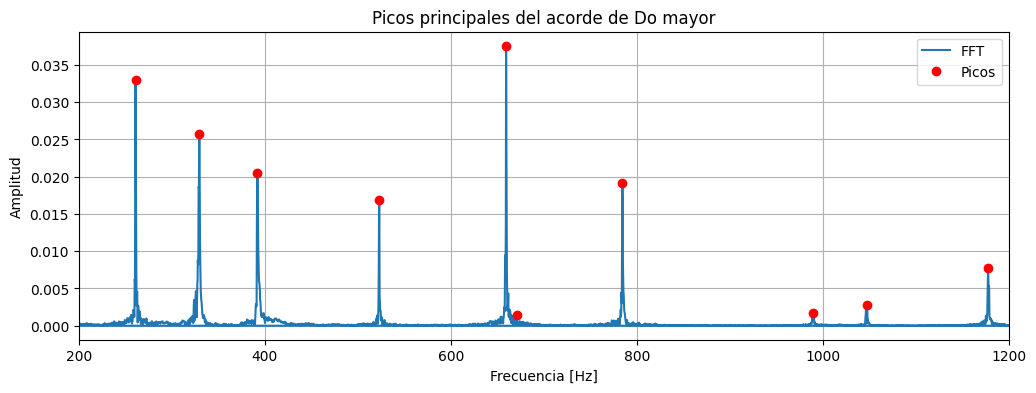

In [ ]:
paso_f = sr / N
picos, propiedades = find_peaks(
    amplitud_pos,
    height=np.max(amplitud_pos) * 0.03,
    prominence=np.max(amplitud_pos) * 0.02,
    distance=max(1, int(10 / paso_f))
)

orden = np.argsort(amplitud_pos[picos])[::-1]

print("Diez picos principales:")
for indice in orden[:10]:
    p = picos[indice]
    print(f"{frecuencias_pos[p]:.2f} Hz -> amplitud {amplitud_pos[p]:.6f}")

plt.figure(figsize=(12, 4))
plt.plot(frecuencias_pos, amplitud_pos, label="FFT")
plt.plot(frecuencias_pos[picos], amplitud_pos[picos], "ro", label="Picos")
plt.xlim(200, 1200)
plt.title("Picos principales del acorde de Do mayor")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()
plt.show()

## 4. Transformada de Fourier con la rutina `FT(x,y)` de clase

En clase se definió la función base

\[
g(t,w)=\frac{1}{2\pi}e^{-i2\pi wt}.
\]

La rutina original calcula por integración las partes real e imaginaria para cada frecuencia. Para evitar tiempos de ejecución excesivos con una señal de audio larga, aquí se modifica la rutina y se aproxima la integral mediante una suma discreta:

\[
F(w)\approx \sum_n y(t_n)g(t_n,w)\,\Delta t.
\]

Se evalúan 601 frecuencias entre 0 y 2000 Hz. La señal se submuestrea tomando una de cada 10 muestras para reducir el tiempo de cálculo. La comparación de amplitudes incluye la normalización necesaria para poner ambas curvas en la misma escala.

In [ ]:
# Función base de Fourier de clase
def g(t, w):
    return (1.0 / (2*np.pi)) * np.exp(-1j * 2*np.pi*w*t)

# Versión discreta de FT(x,y), modificada para datos muestreados
def FT(x, y, w):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y)
    w = np.asarray(w, dtype=float)

    dt = x[1] - x[0]
    resultados = []

    for frecuencia_actual in w:
        Fw = np.sum(y * g(x, frecuencia_actual)) * dt
        resultados.append([
            frecuencia_actual,
            Fw.real,
            Fw.imag,
            np.abs(Fw),
            np.angle(Fw)
        ])

    return pd.DataFrame(
        resultados,
        columns=["w", "ReTw", "ImTw", "AMP", "ANG"]
    )

# Reducir el número de muestras para agilizar la integración numérica
factor_muestreo = 10
t_FT = t[::factor_muestreo]
signal_FT = signal[::factor_muestreo]

w = np.linspace(0, 2000, 601)
df_audio = FT(t_FT, signal_FT, w)

# Normalización para comparar con el espectro unilateral de la FFT
dt_FT = t_FT[1] - t_FT[0]
df_audio["AMP_norm"] = df_audio["AMP"] * 4*np.pi / (len(signal_FT)*dt_FT)

display(df_audio.head())

,w,ReTw,ImTw,AMP,ANG,AMP_norm
0,0.000000,0.000044,0.000000,0.000044,0.000000,0.000161
1,3.333333,0.000084,-0.000119,0.000146,-0.956805,0.000531
2,6.666667,-0.000114,-0.000010,0.000114,-3.057627,0.000416
3,10.000000,-0.000028,0.000058,0.000064,2.020642,0.000233
4,13.333333,0.000009,0.000050,0.000050,1.398319,0.000184


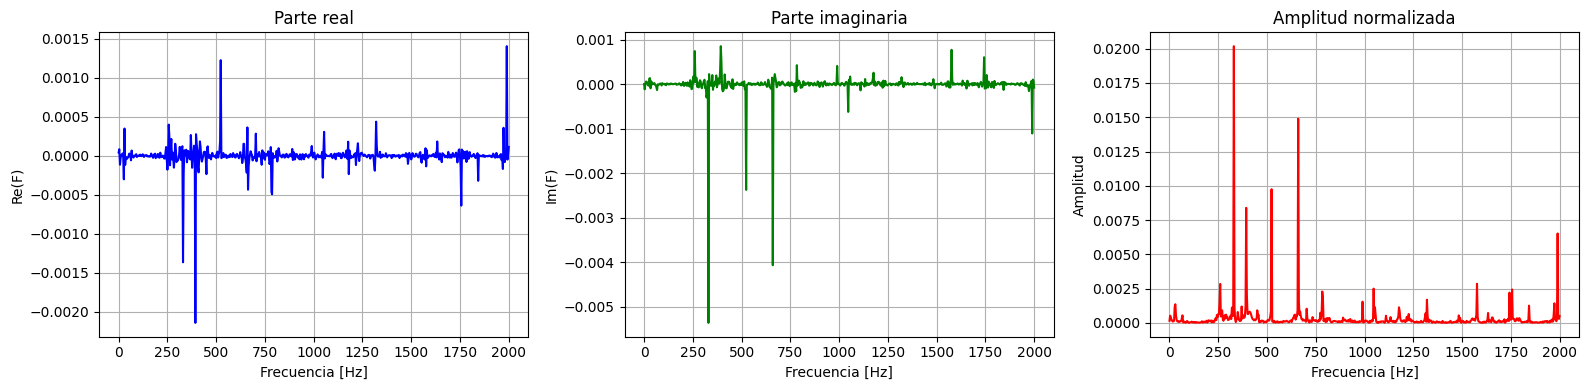

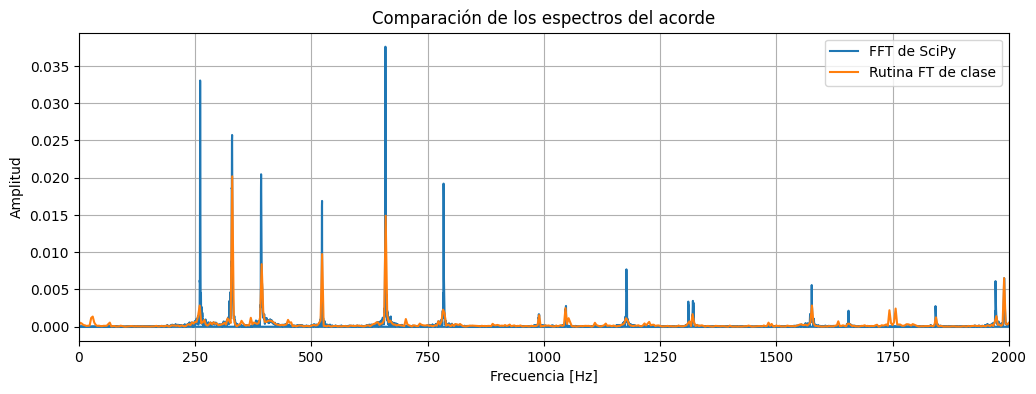

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(df_audio.w, df_audio.ReTw, color="blue")
ax[0].set_title("Parte real")
ax[0].set_xlabel("Frecuencia [Hz]")
ax[0].set_ylabel("Re(F)")
ax[0].grid(True)

ax[1].plot(df_audio.w, df_audio.ImTw, color="green")
ax[1].set_title("Parte imaginaria")
ax[1].set_xlabel("Frecuencia [Hz]")
ax[1].set_ylabel("Im(F)")
ax[1].grid(True)

ax[2].plot(df_audio.w, df_audio.AMP_norm, color="red")
ax[2].set_title("Amplitud normalizada")
ax[2].set_xlabel("Frecuencia [Hz]")
ax[2].set_ylabel("Amplitud")
ax[2].grid(True)

plt.tight_layout()
plt.show()

# Comparación directa de amplitudes
plt.figure(figsize=(12, 4))
plt.plot(frecuencias_pos, amplitud_pos, label="FFT de SciPy")
plt.plot(df_audio.w, df_audio.AMP_norm, label="Rutina FT de clase")
plt.xlim(0, 2000)
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Amplitud")
plt.title("Comparación de los espectros del acorde")
plt.grid(True)
plt.legend()
plt.show()

### Conclusión del ejemplo de audio

NumPy y SciPy deben producir el mismo espectro porque calculan la misma FFT. La rutina de clase aproxima la transformada mediante una suma discreta y evalúa un conjunto de frecuencias elegido. Por eso, su curva puede presentar diferencias de resolución y amplitud respecto a la FFT. Al aumentar el número de frecuencias evaluadas se obtiene una curva más detallada en el intervalo analizado, aunque esto no crea nuevas componentes en la señal. La posición de los picos depende de las frecuencias presentes en el sonido y de la resolución de la medición.

---

# Exercise 1: FFT de una imagen


## 5. Cargar la imagen

Saving 9c8295b229e525b3998aaf6aafaaa20a.jpg to 9c8295b229e525b3998aaf6aafaaa20a (1).jpg
Imagen seleccionada: 9c8295b229e525b3998aaf6aafaaa20a (1).jpg
Tamaño original (ancho x alto): (736, 736)


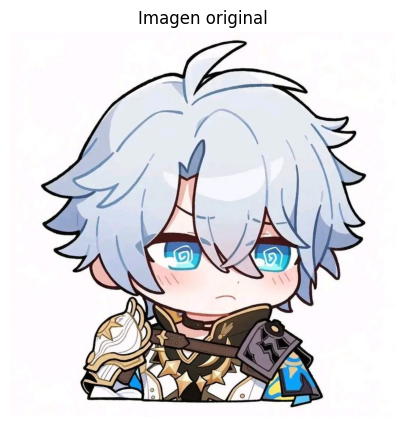

In [ ]:
archivos_imagen = files.upload()

if not archivos_imagen:
    raise ValueError("No se seleccionó ninguna imagen.")

nombre_imagen = next(iter(archivos_imagen))
imagen_color = Image.open(BytesIO(archivos_imagen[nombre_imagen])).convert("RGB")

print("Imagen seleccionada:", nombre_imagen)
print("Tamaño original (ancho x alto):", imagen_color.size)

plt.figure(figsize=(7, 5))
plt.imshow(imagen_color)
plt.title("Imagen original")
plt.axis("off")
plt.show()

## 6. Preparación de la imagen

Tamaño de la matriz analizada: (700, 700)
Valor mínimo: 0.0
Valor máximo: 1.0


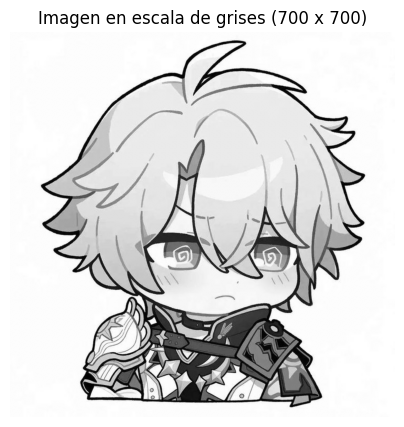

In [ ]:
tamano = 700

imagen_gris = imagen_color.convert("L")
imagen_gris = imagen_gris.resize((tamano, tamano), Image.Resampling.LANCZOS)
imagen = np.asarray(imagen_gris, dtype=float) / 255.0

print("Tamaño de la matriz analizada:", imagen.shape)
print("Valor mínimo:", imagen.min())
print("Valor máximo:", imagen.max())

plt.figure(figsize=(5, 5))
plt.imshow(imagen, cmap="gray", vmin=0, vmax=1)
plt.title(f"Imagen en escala de grises ({tamano} x {tamano})")
plt.axis("off")
plt.show()

## 7. FFT bidimensional usando NumPy y SciPy

Una imagen es una matriz de intensidad luminosa, por lo que su transformada de Fourier es bidimensional. El espectro permite visualizar las frecuencias espaciales presentes en la imagen. Se centra el origen de frecuencias con `fftshift` para facilitar su interpretación.

Error máximo entre NumPy y SciPy: 1.524590935718171e-11


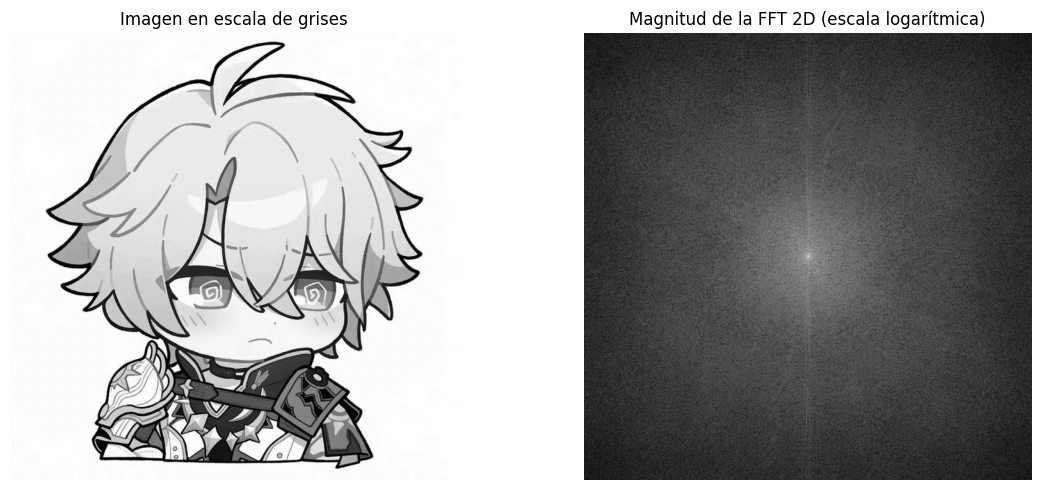

In [ ]:
F_numpy_2D = np.fft.fft2(imagen)
F_scipy = fft2(imagen)

error_fft_imagen = np.max(np.abs(F_numpy_2D - F_scipy))
print("Error máximo entre NumPy y SciPy:", error_fft_imagen)

F_scipy_centrada = fftshift(F_scipy)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=1)
plt.title("Imagen en escala de grises")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(F_scipy_centrada)), cmap="gray")
plt.title("Magnitud de la FFT 2D (escala logarítmica)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Transformada de Fourier usando la rutina de clase

Para extender la rutina `FT(x,y,w)` a dos dimensiones, se aplica primero a cada fila de la imagen y luego a cada columna del resultado. De esta manera se obtiene la transformada bidimensional. La función base incluye un factor \(1/(2\pi)\) en cada dimensión. Para comparar el resultado con `fft2`, se compensa ese factor multiplicando por \((2\pi)^2\).

In [ ]:
def FT2D(im):
    Nx, Ny = im.shape

    x = np.arange(Nx, dtype=float)
    y = np.arange(Ny, dtype=float)

    wx = np.fft.fftfreq(Nx, d=1.0)
    wy = np.fft.fftfreq(Ny, d=1.0)

    # Transformada de cada fila
    F_filas = np.zeros((Nx, Ny), dtype=complex)

    for i in range(Nx):
        df_fila = FT(y, im[i, :], wy)
        F_filas[i, :] = df_fila["ReTw"].to_numpy() + 1j*df_fila["ImTw"].to_numpy()

    # Transformada de cada columna
    F_columnas = np.zeros((Nx, Ny), dtype=complex)

    for j in range(Ny):
        df_columna = FT(x, F_filas[:, j], wx)
        F_columnas[:, j] = df_columna["ReTw"].to_numpy() + 1j*df_columna["ImTw"].to_numpy()

    return F_columnas

F_clase = FT2D(imagen)
F_clase_comparar = F_clase * (2*np.pi)**2

error_relativo = (
    np.max(np.abs(F_clase_comparar - F_scipy))
    / np.max(np.abs(F_scipy))
)

print("Error relativo entre FT de clase y SciPy:", error_relativo)

Error relativo entre FT de clase y SciPy: 8.585330579440894e-15


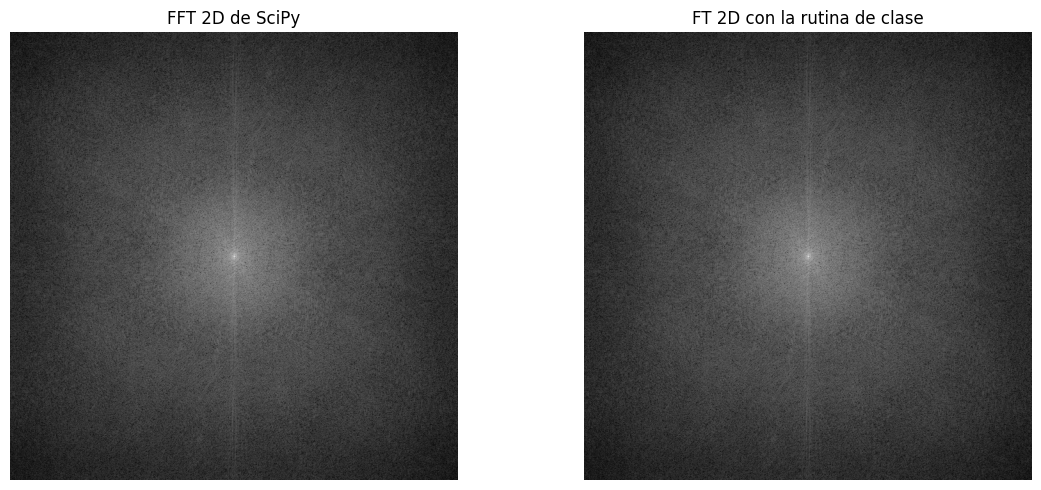

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(np.log1p(np.abs(fftshift(F_scipy))), cmap="gray")
plt.title("FFT 2D de SciPy")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(fftshift(F_clase_comparar))), cmap="gray")
plt.title("FT 2D con la rutina de clase")
plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Transformada inversa y reconstrucción de la imagen

Se aplica la transformada inversa bidimensional a la FFT calculada con SciPy. Se compara la imagen reconstruida con la matriz original utilizada en el cálculo. El error absoluto se calcula píxel por píxel.

Error máximo: 1.5543122344752192e-15
Error medio: 2.5222436698570927e-16
Máxima parte imaginaria residual: 3.9688845658689095e-16


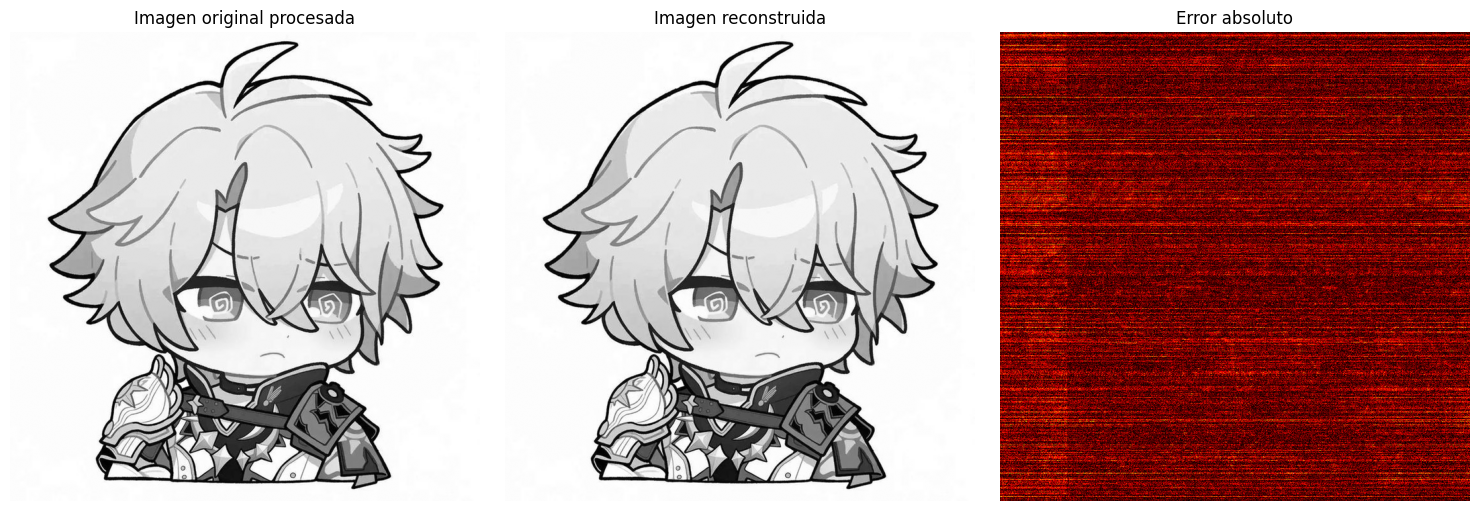

In [ ]:
imagen_recuperada_compleja = ifft2(F_scipy)
imagen_recuperada = imagen_recuperada_compleja.real

error = np.abs(imagen - imagen_recuperada)

print("Error máximo:", np.max(error))
print("Error medio:", np.mean(error))
print("Máxima parte imaginaria residual:", np.max(np.abs(imagen_recuperada_compleja.imag)))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap="gray", vmin=0, vmax=1)
plt.title("Imagen original procesada")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_recuperada, cmap="gray", vmin=0, vmax=1)
plt.title("Imagen reconstruida")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(error, cmap="hot")
plt.title("Error absoluto")
plt.axis("off")

plt.tight_layout()
plt.show()

 Conclusiones del ejercicio

**1. FFT con NumPy y SciPy.** Las dos implementaciones calculan la misma transformada. El error máximo permite verificar que las diferencias se encuentran en la precisión numérica de los cálculos.

**2. Rutina de clase.** La rutina `FT` se adaptó a una matriz bidimensional aplicándola por filas y columnas. La comparación de los espectros permite comprobar si ambas implementaciones presentan una distribución de frecuencias espaciales semejante. Las diferencias pueden relacionarse con la aproximación numérica de la integral y la normalización.

**3. Transformada inversa.** La imagen reconstruida debe ser prácticamente igual a la imagen procesada. Un error máximo y medio muy pequeños indican que la transformada inversa recupera correctamente los valores de la matriz original.

**Nota:** la comparación de reconstrucción se hace con la imagen en escala de grises y redimensionada a 700 × 700 píxeles, que es la matriz que se transformó. No se compara con la fotografía original a color y en su resolución inicial.